Tổng số ảnh toàn bộ: 2137
Số lượng ảnh Train: 1584 | Val: 292 | Test: 261


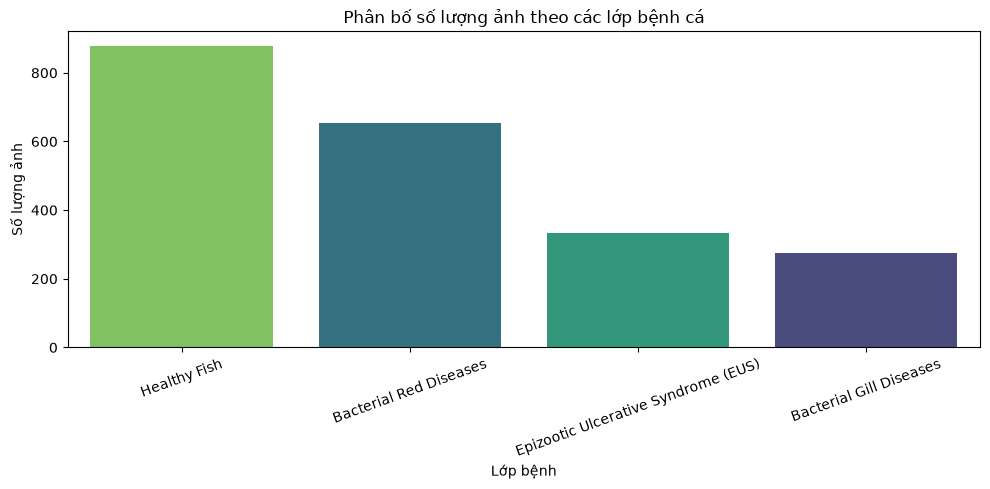

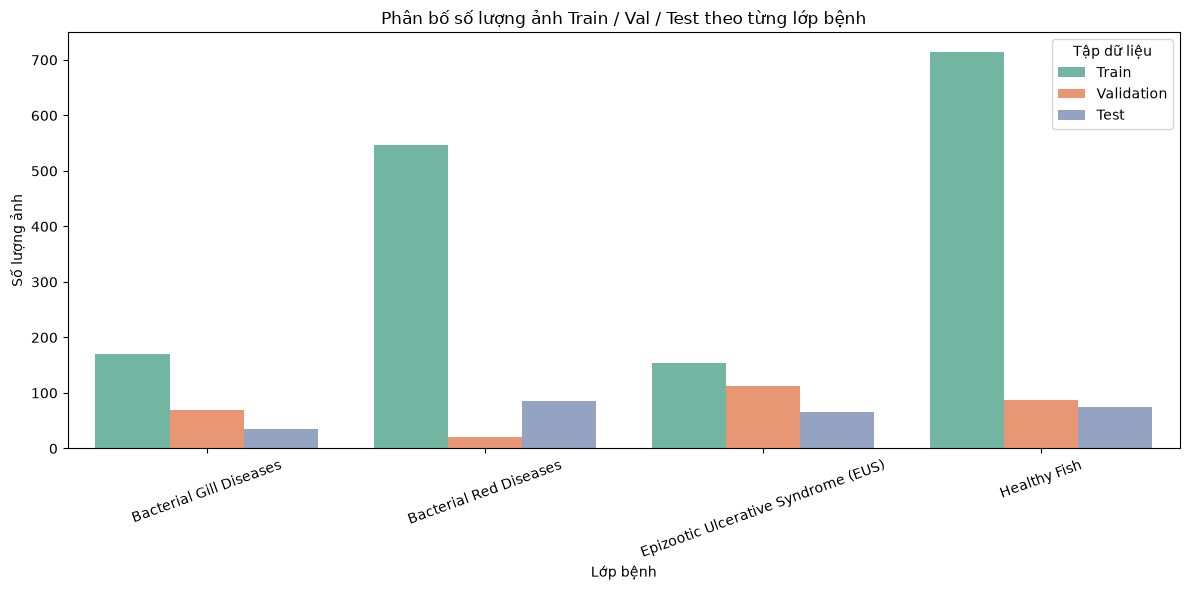


Đã lưu các biểu đồ EDA vào thư mục reports/ thành công! Bạn có thể lấy ảnh đó đưa vào báo cáo.


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đảm bảo đứng ở thư mục gốc Project
if os.path.basename(os.getcwd()) == "notebook" or os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Tạo thư mục reports nếu chưa có để lưu biểu đồ
reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Đọc file metadata và các file splits đã tạo
df_meta = pd.read_csv("data/metadata_clean.csv")
df_train = pd.read_csv("data/splits/train.csv")
df_val = pd.read_csv("data/splits/val.csv")
df_test = pd.read_csv("data/splits/test.csv")

print(f"Tổng số ảnh toàn bộ: {len(df_meta)}")
print(f"Số lượng ảnh Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# 1. Vẽ biểu đồ phân bố số lượng ảnh theo lớp bệnh (Overall)
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_meta, 
    x='class_name', 
    order=df_meta['class_name'].value_counts().index, 
    hue='class_name',      # Thêm hue để tránh cảnh báo phiên bản mới của seaborn
    palette='viridis', 
    legend=False           # Ẩn chú thích thừa
)
plt.title("Phân bố số lượng ảnh theo các lớp bệnh cá")
plt.xlabel("Lớp bệnh")
plt.ylabel("Số lượng ảnh")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(reports_dir / "class_distribution.png", dpi=300)
plt.show()

# 2. Vẽ biểu đồ so sánh tỷ lệ Train / Validation / Test theo lớp
df_train['split'] = 'Train'
df_val['split'] = 'Validation'
df_test['split'] = 'Test'
df_all_splits = pd.concat([df_train, df_val, df_test])

plt.figure(figsize=(12, 6))
sns.countplot(data=df_all_splits, x='class_name', hue='split', palette='Set2')
plt.title("Phân bố số lượng ảnh Train / Val / Test theo từng lớp bệnh")
plt.xlabel("Lớp bệnh")
plt.ylabel("Số lượng ảnh")
plt.xticks(rotation=20)
plt.legend(title="Tập dữ liệu")
plt.tight_layout()
plt.savefig(reports_dir / "splits_distribution.png", dpi=300)
plt.show()

print("\nĐã lưu các biểu đồ EDA vào thư mục reports/ thành công! Bạn có thể lấy ảnh đó đưa vào báo cáo.")

--- THỐNG KÊ SỐ LƯỢNG ẢNH TRÊN MỖI SPECIMEN ---
                                     count       mean        std   min   25%  \
class_name                                                                     
Bacterial Gill Diseases               27.0   5.814815   1.687899   3.0   5.0   
Bacterial Red Diseases                35.0  10.771429   5.145448   4.0   7.5   
Epizootic Ulcerative Syndrome (EUS)   14.0  12.642857   7.761910   4.0   6.5   
Healthy Fish                          10.0  49.000000  17.857460  26.0  37.0   

                                      50%    75%   max  
class_name                                              
Bacterial Gill Diseases               6.0   7.00   9.0  
Bacterial Red Diseases               10.0  13.00  24.0  
Epizootic Ulcerative Syndrome (EUS)  12.5  15.75  34.0  
Healthy Fish                         47.5  62.00  81.0  


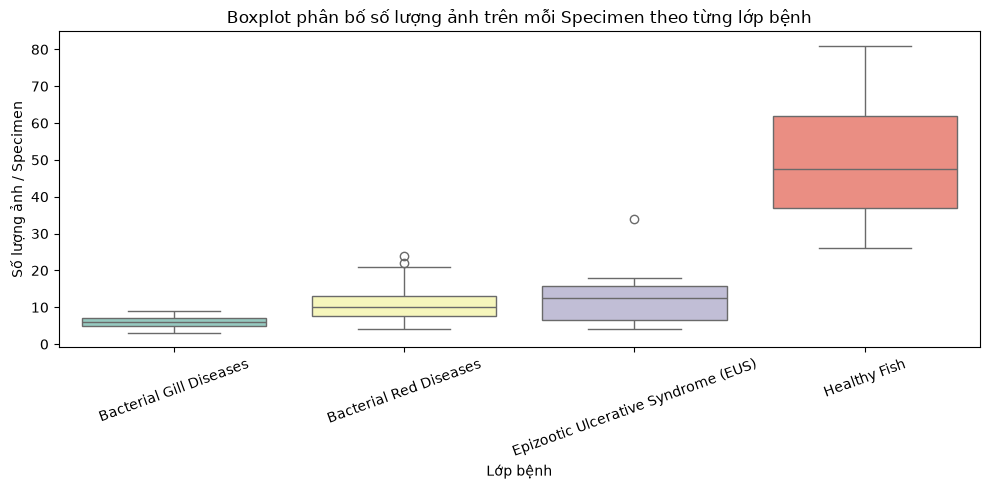

In [4]:
#Thống kê và vẽ Boxplot / Histogram số ảnh trên mỗi specimen theo từng bệnh
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

# Đưa thư mục làm việc về thư mục gốc của project (nếu đang đứng ở thư mục notebook)
if os.path.basename(os.getcwd()) == "notebook" or os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Thiết lập thư mục reports
reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Đọc file metadata sạch từ thư mục gốc
df_meta = pd.read_csv("data/metadata_clean.csv")

# Tính số lượng ảnh trên mỗi specimen
spec_counts = df_meta.groupby(['class_name', 'specimen_id'])['filename'].count().reset_index(name='num_images')

print("--- THỐNG KÊ SỐ LƯỢNG ẢNH TRÊN MỖI SPECIMEN ---")
print(spec_counts.groupby('class_name')['num_images'].describe())

# Vẽ Boxplot số ảnh/specimen theo từng bệnh
plt.figure(figsize=(10, 5))
sns.boxplot(data=spec_counts, x='class_name', y='num_images', palette='Set3', hue='class_name', legend=False)
plt.title("Boxplot phân bố số lượng ảnh trên mỗi Specimen theo từng lớp bệnh")
plt.xlabel("Lớp bệnh")
plt.ylabel("Số lượng ảnh / Specimen")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(reports_dir / "specimen_images_boxplot.png", dpi=300)
plt.show()

In [8]:
#Tính tỷ lệ phần trăm (%) từng lớp trong Train / Val / Test
import os
import pandas as pd
from pathlib import Path

# Đưa thư mục làm việc về thư mục gốc của project (nếu đang đứng ở thư mục notebook)
if os.path.basename(os.getcwd()) == "notebook" or os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Đọc các file split đã chia
df_train = pd.read_csv("data/splits/train.csv")
df_val = pd.read_csv("data/splits/val.csv")
df_test = pd.read_csv("data/splits/test.csv")

# Gán nhãn split
df_train['split'] = 'Train'
df_val['split'] = 'Validation'
df_test['split'] = 'Test'
df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)

# Tính bảng số lượng bằng pivot_table (an toàn hơn crosstab khi có nhãn lặp)
pivot_count = df_all.pivot_table(
    index='class_name', 
    columns='split', 
    values='filename', 
    aggfunc='count', 
    fill_value=0
)

# Thêm cột tổng số lượng (Total)
pivot_count['Total'] = pivot_count.sum(axis=1)

# Tính bảng tỷ lệ phần trăm (%) theo từng cột
pivot_pct = (pivot_count[['Train', 'Validation', 'Test']].div(pivot_count[['Train', 'Validation', 'Test']].sum(axis=0), axis=1)) * 100

print("=== BẢNG SỐ LƯỢNG ẢNH THEO TỪNG TẬP ===")
print(pivot_count)

print("\n=== BẢNG TỶ LỆ PHẦN TRĂM (%) CỦA TỪNG LỚP TRONG TRAIN / VAL / TEST ===")
print(pivot_pct.round(2).astype(str) + "%")

=== BẢNG SỐ LƯỢNG ẢNH THEO TỪNG TẬP ===
split                                Test  Train  Validation  Total
class_name                                                         
Bacterial Gill Diseases                31    107          19    157
Bacterial Red Diseases                 83    247          47    377
Epizootic Ulcerative Syndrome (EUS)    35    121          21    177
Healthy Fish                           76    388          26    490

=== BẢNG TỶ LỆ PHẦN TRĂM (%) CỦA TỪNG LỚP TRONG TRAIN / VAL / TEST ===
split                                 Train Validation    Test
class_name                                                    
Bacterial Gill Diseases               12.4%     16.81%  13.78%
Bacterial Red Diseases               28.62%     41.59%  36.89%
Epizootic Ulcerative Syndrome (EUS)  14.02%     18.58%  15.56%
Healthy Fish                         44.96%     23.01%  33.78%


In [10]:
#Kiểm tra duplicate / pHash giữa ba tập (Train / Val / Test)
# Kiểm tra giao nhau về tên file hoặc đường dẫn ảnh giữa các tập
train_paths = set(df_train['image_path'])
val_paths = set(df_val['image_path'])
test_paths = set(df_test['image_path'])

train_val_dup = train_paths.intersection(val_paths)
train_test_dup = train_paths.intersection(test_paths)
val_test_dup = val_paths.intersection(test_paths)

print("=== KIỂM TRA DUPLICATE GIỮA BA TẬP (TRAIN / VAL / TEST) ===")
print(f"Số ảnh trùng giữa Train và Val: {len(train_val_dup)}")
print(f"Số ảnh trùng giữa Train và Test: {len(train_test_dup)}")
print(f"Số ảnh trùng giữa Val và Test: {len(val_test_dup)}")

if len(train_val_dup) == 0 and len(train_test_dup) == 0 and len(val_test_dup) == 0:
    print(">>> KẾT LUẬN: Không phát hiện duplicate ảnh giữa 3 tập Train, Val, Test. Đạt chuẩn!")
else:
    print(">>> CẢNH BÁO: Phát hiện ảnh trùng lặp giữa các tập!")

=== KIỂM TRA DUPLICATE GIỮA BA TẬP (TRAIN / VAL / TEST) ===
Số ảnh trùng giữa Train và Val: 0
Số ảnh trùng giữa Train và Test: 0
Số ảnh trùng giữa Val và Test: 0
>>> KẾT LUẬN: Không phát hiện duplicate ảnh giữa 3 tập Train, Val, Test. Đạt chuẩn!


=== THỐNG KÊ PHÂN BỐ LOÀI CÁ (SPECIES) ===
                                  species  num_images
                       Rui_(Labeo rohita)         425
Silver_carp_(Hypophthalmichthys molitrix)         305
     Grass_carp_(Ctenopharyngodon idella)         294
      Epizootic Ulcerative Syndrome (EUS)         177


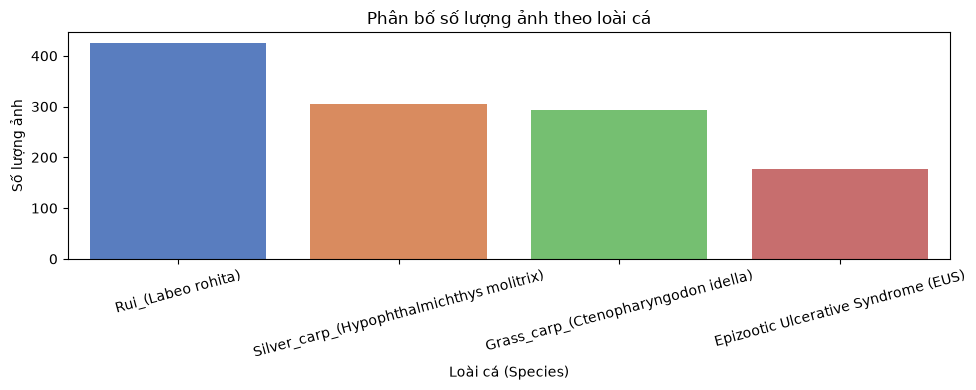

In [11]:
#Thống kê phân bố loài cá (Species) từ cấu trúc đường dẫn
# Trích xuất thông tin loài từ cột image_path (giả định cấu trúc thư mục chứa tên loài)
def extract_species(path_str):
    parts = Path(path_str).parts
    # Tìm phần tử chứa tên loài (thường nằm ở vị trí sau lớp bệnh hoặc chứa dấu ngoặc)
    for part in parts:
        if '(' in part and ')' in part:
            return part
    return "Unknown_Species"

df_meta['species'] = df_meta['image_path'].apply(extract_species)

print("=== THỐNG KÊ PHÂN BỐ LOÀI CÁ (SPECIES) ===")
species_counts = df_meta['species'].value_counts().reset_index(name='num_images')
print(species_counts.to_string(index=False))

# Vẽ biểu đồ phân bố loài
plt.figure(figsize=(10, 4))
sns.barplot(data=species_counts, x='species', y='num_images', palette='muted', hue='species', legend=False)
plt.title("Phân bố số lượng ảnh theo loài cá")
plt.xlabel("Loài cá (Species)")
plt.ylabel("Số lượng ảnh")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(reports_dir / "species_distribution.png", dpi=300)
plt.show()